<a href="https://colab.research.google.com/github/Rogerkamana/Assignment4_rk/blob/main/Lesson_7_assignment_rk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Assignment Supervised machine Learning - Regression**

### **_House Price Prediction Using Bolton Housing Data_**
This dataset provides information about house prices in Bolton. House Price Prediction


**In this notebook, you'll follow the basic machine learning process to build a regression model to predict house prices using the "Boston Housing Dataset" from sklearn. The regression model will either be a Decision Tree or Random Forest regressor.**



---



### **Follow the instructions and complete each TODO to complete the assessment on the essential steps in building and evaluating a regression model.**


The following is a description of each column in the dataset:

Dataset Features (Bolton Housing):

* CRIM: Crime rate by town
* ZN: Proportion of residential land zoned for large lots
* INDUS: Proportion of non-retail business acres per town
* CHAS: Charles River dummy variable (1 if tract bounds river; 0 otherwise)
* NOX: Nitric oxide concentration (parts per 10 million)
* RM: Average number of rooms per dwelling
* AGE: Proportion of owner-occupied units built before 1940
* DIS: Weighted distances to five Boston employment centers
* RAD: Index of accessibility to radial highways
* TAX: Full-value property tax rate per `$10,000`
* PTRATIO: Pupil-teacher ratio by town
* B: Proportion of Black population
* LSTAT: Percentage of lower status of the population
* MEDV (Target): Median value of owner-occupied homes in `$1,000s`



**Dataset is from sklearn Datasets**

## 1. Imports

In [1]:
import math

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split

## 2. Data Collection and Loading
_Load the 'Boston Housing' dataset from sklearn and convert it into a pandas DataFrame._

In [2]:
dataset_url = (
    "https://raw.githubusercontent.com/scikit-learn/scikit-learn/1.1.3/"
    "sklearn/datasets/data/boston_house_prices.csv"
)
housing = pd.read_csv(dataset_url, skiprows=1)
target = "MEDV"
features = housing.columns.drop(target).tolist()

print(f"Rows: {len(housing)} | Features: {len(features)} | Target: {target}")

Rows: 506 | Features: 13 | Target: MEDV


## 3. Quick Check of Data
_3.1:Display the first few rows of the dataset to understand its structure._

_3.2: Check the features and target variable. Identify which is continuous and categorical if applicable._


In [4]:
display(housing.head())
housing.info()
display(housing.describe().T.round(2))

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


,count,mean,std,min,25%,50%,75%,max
CRIM,506.0,3.61,8.60,0.01,0.08,0.26,3.68,88.98
ZN,506.0,11.36,23.32,0.00,0.00,0.00,12.50,100.00
INDUS,506.0,11.14,6.86,0.46,5.19,9.69,18.10,27.74
CHAS,506.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00
NOX,506.0,0.55,0.12,0.38,0.45,0.54,0.62,0.87
RM,506.0,6.28,0.70,3.56,5.89,6.21,6.62,8.78
AGE,506.0,68.57,28.15,2.90,45.02,77.50,94.07,100.00
DIS,506.0,3.80,2.11,1.13,2.10,3.21,5.19,12.13
RAD,506.0,9.55,8.71,1.00,4.00,5.00,24.00,24.00
TAX,506.0,408.24,168.54,187.00,279.00,330.00,666.00,711.00


## 4. EDA and Data Preprocessing
_4.1. Check for missing/null values._

_4.2. Visualize the data. Create scatter plots to see the relationship between independent features and the target variable._

_4.3. Create a function to automate scatter plots for all features vs the target variable._

_4.4. Use the function to visualize the relationships between multiple features and the target variable._

In [5]:
missing_values = housing.isnull().sum()
display(missing_values.to_frame("Missing values"))
print(f"Total missing values: {missing_values.sum()}")

,Missing values
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


Total missing values: 0


The dataset has no missing values, so no imputation is required. The Random Forest can use the binary indicator and the numerical features as stored, with no feature scaling.

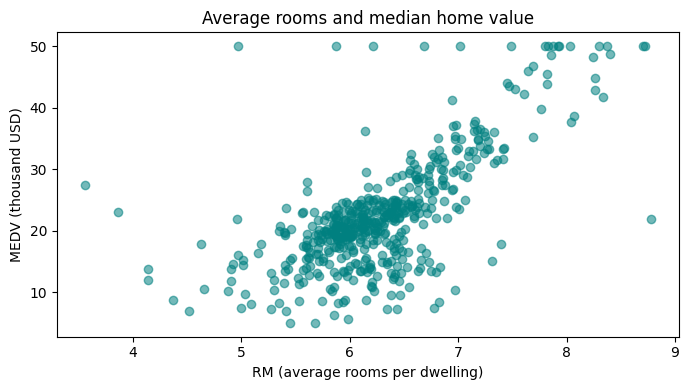

In [6]:
plt.figure(figsize=(7, 4))
plt.scatter(housing["RM"], housing[target], alpha=0.55, color="teal")
plt.xlabel("RM (average rooms per dwelling)")
plt.ylabel("MEDV (thousand USD)")
plt.title("Average rooms and median home value")
plt.tight_layout()
plt.show()

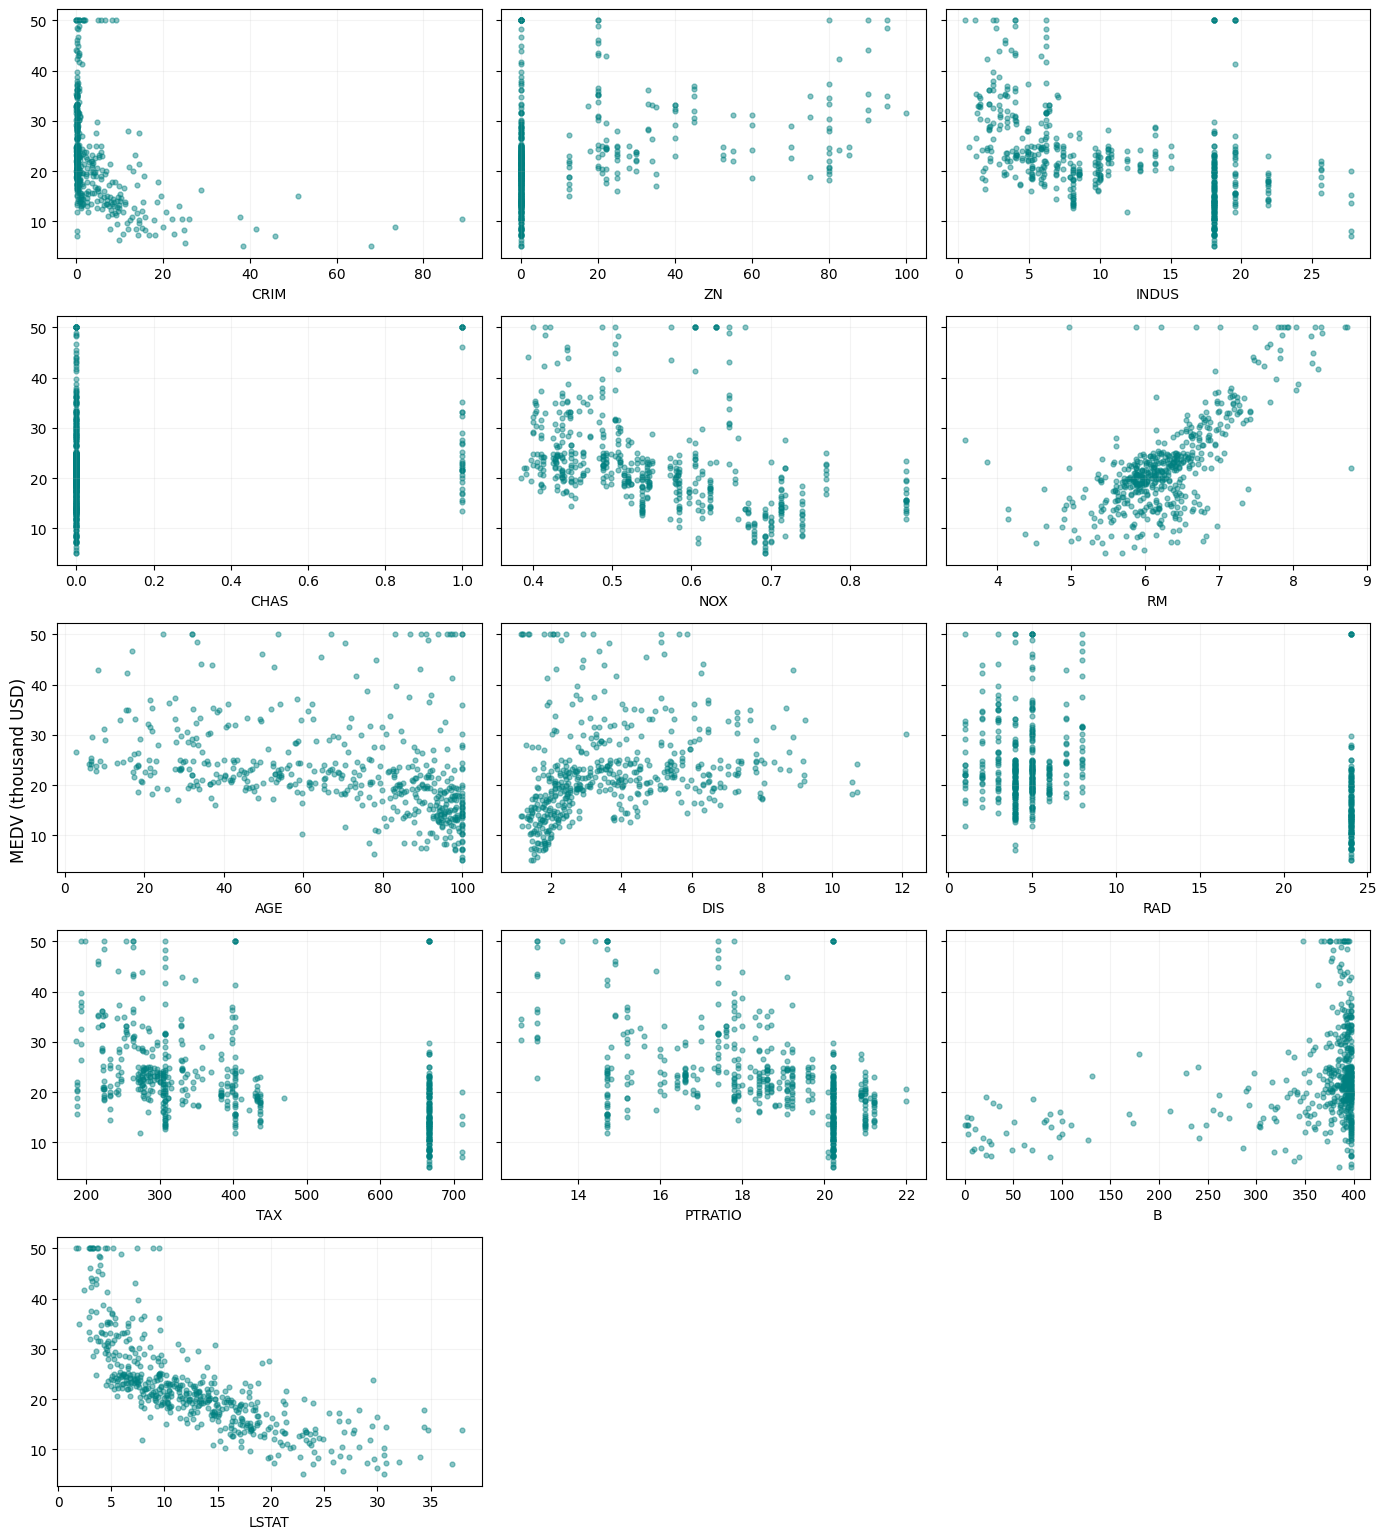

In [7]:
def plot_feature_scatter(data, feature_columns, target_column, columns=3):
    # Plot each selected feature against the target in its own panel.
    rows = math.ceil(len(feature_columns) / columns)
    fig, axes = plt.subplots(
        rows, columns, figsize=(4.7 * columns, 3.1 * rows),
        sharey=True, squeeze=False,
    )
    for ax, feature in zip(axes.flat, feature_columns):
        ax.scatter(data[feature], data[target_column], s=12, alpha=0.45, color="teal")
        ax.set_xlabel(feature)
        ax.grid(alpha=0.15)
    for ax in list(axes.flat)[len(feature_columns):]:
        ax.set_visible(False)
    fig.supylabel(f"{target_column} (thousand USD)")
    fig.tight_layout()
    plt.show()


plot_feature_scatter(housing, features, target)

Median home values tend to rise with `RM` and fall as `LSTAT` increases. Several observations are recorded at the dataset's upper limit of $50,000, producing a horizontal band in the scatter plots. These plots show associations.

## 5. ML Model Training

_5.1. Split the dataset into training and testing sets._

The data are split into 80% training and 20% testing. A Random Forest averages predictions from multiple decision trees and can capture nonlinear relationships such as those seen in the scatter plots.

_5.2. Choose an appropriate regression model:_

  _1.Decision Tree or Random Forest_

  _2.Train the model on the training data._


In [9]:
X = housing[features]
y = housing[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

forest = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=1)
forest.fit(X_train, y_train)

print(f"Training observations: {len(X_train)}")
print(f"Test observations: {len(X_test)}")

Training observations: 404
Test observations: 102


## 6. Model Evaluation

_6.1.Evaluate the performance of the model on the test set using relevant metrics (e.g., RMSE, R-squared)._

_6.2.Perform parameter tuning on the model if needed to improve the performance of your model._

In [10]:
parameter_grid = {
    "max_depth": [None, 8, 16],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [1.0, 0.7],
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(
    forest, parameter_grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1
)
search.fit(X_train, y_train)
final_model = search.best_estimator_

print("Selected parameters:", search.best_params_)
print(f"Mean validation RMSE: {-search.best_score_:.2f} thousand USD")

Selected parameters: {'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 1}
Mean validation RMSE: 3.58 thousand USD


In [ ]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)
    return {
        "RMSE (thousand USD)": math.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions),
    }


results = pd.DataFrame.from_dict(
    {
        "Baseline Random Forest": evaluate_model(forest, X_test, y_test),
        "Tuned Random Forest": evaluate_model(final_model, X_test, y_test),
    },
    orient="index",
)
display(results.round(3))

test_rmse, test_r2 = results.loc["Tuned Random Forest"]
print(f"The tuned model's test RMSE is approximately ${test_rmse * 1_000:,.0f}.")
print(f"It explains {test_r2:.1%} of the variation in MEDV on the test set.")

,RMSE (thousand USD),R²
Baseline Random Forest,2.811,0.892
Tuned Random Forest,2.701,0.900


The tuned model's test RMSE is approximately $2,701.
It explains 90.0% of the variation in MEDV on the test set.


## 7. Model Prediction

_Predict house prices from a new set of feature inputs._



In [11]:
new_tract = pd.DataFrame([{
    "CRIM": 0.2,
    "ZN": 12.5,
    "INDUS": 7.07,
    "CHAS": 0,
    "NOX": 0.5,
    "RM": 6.5,
    "AGE": 68,
    "DIS": 4.0,
    "RAD": 2,
    "TAX": 250,
    "PTRATIO": 17,
    "B": 400,
    "LSTAT": 12,
}], columns=features)

display(new_tract)
prediction = final_model.predict(new_tract)[0]
print(f"Predicted MEDV: {prediction:.2f} thousand USD (${prediction * 1_000:,.0f})")

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.2,12.5,7.07,0,0.5,6.5,68,4.0,2,250,17,400,12


Predicted MEDV: 22.77 thousand USD ($22,769)
